In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# EDA


In [ ]:
loc = '/content/Telco-Customer-Churn.csv'
df = pd.read_csv(loc)
print(df)

      customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
0              No  No phone service             DSL             No  ...   
1        

df.head(10)

In [ ]:
df.shape

(7043, 21)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### Profile categorical columns


In [ ]:
cat_cols = df.select_dtypes(include="object").columns.drop("customerID")

for col in cat_cols:
    print(f"{col}: {df[col].nunique()} unique -> {df[col].unique().tolist()}")


gender: 2 unique -> ['Female', 'Male']
Partner: 2 unique -> ['Yes', 'No']
Dependents: 2 unique -> ['No', 'Yes']
PhoneService: 2 unique -> ['No', 'Yes']
MultipleLines: 3 unique -> ['No phone service', 'No', 'Yes']
InternetService: 3 unique -> ['DSL', 'Fiber optic', 'No']
OnlineSecurity: 3 unique -> ['No', 'Yes', 'No internet service']
OnlineBackup: 3 unique -> ['Yes', 'No', 'No internet service']
DeviceProtection: 3 unique -> ['No', 'Yes', 'No internet service']
TechSupport: 3 unique -> ['No', 'Yes', 'No internet service']
StreamingTV: 3 unique -> ['No', 'Yes', 'No internet service']
StreamingMovies: 3 unique -> ['No', 'Yes', 'No internet service']
Contract: 3 unique -> ['Month-to-month', 'One year', 'Two year']
PaperlessBilling: 2 unique -> ['Yes', 'No']
PaymentMethod: 4 unique -> ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
TotalCharges: 6531 unique -> ['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.0

In [ ]:
df["TotalCharges"].value_counts()

,count
TotalCharges,
,11
20.2,11
19.75,9
20.05,8
19.9,8
...,...
130.15,1
3211.9,1
7843.55,1


In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


### Investigate the missing TotalCharges values


In [ ]:
df[df["TotalCharges"].isnull()][["tenure", "MonthlyCharges", "TotalCharges"]]


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


All 11 rows with a missing TotalCharges have tenure == 0 — they're brand-new customers who haven't been billed yet. Since TotalCharges should equal roughly MonthlyCharges * tenure, it's reasonable to either drop these rows (they carry almost no signal) or impute them with 0. We drop them in preprocessing below, since 11 rows out of 7043 is negligible (~0.16%).

In [ ]:
df["customerID"].duplicated().sum()

np.int64(0)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [ ]:
df["Churn"].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


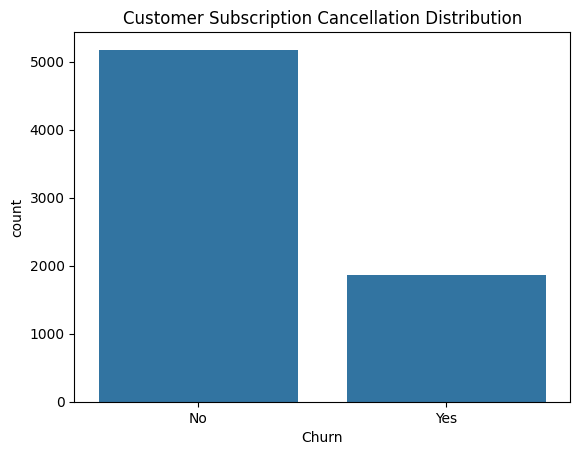

In [ ]:
sns.countplot(data=df, x="Churn")
plt.title("Customer Subscription Cancellation Distribution")
plt.show()

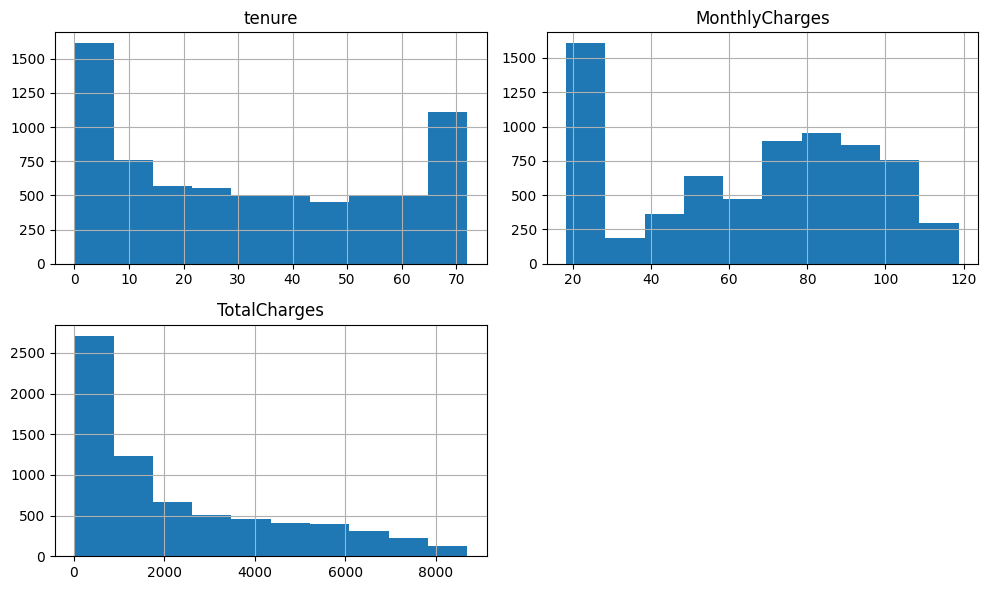

In [ ]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].hist(
    figsize=(10, 6)
)

plt.tight_layout()
plt.show()

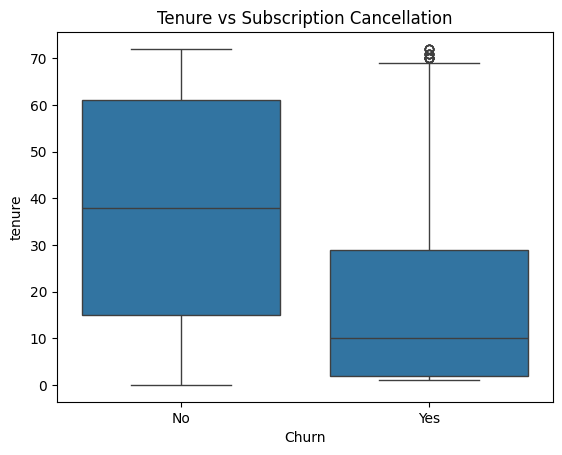

In [ ]:
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Tenure vs Subscription Cancellation")
plt.show()

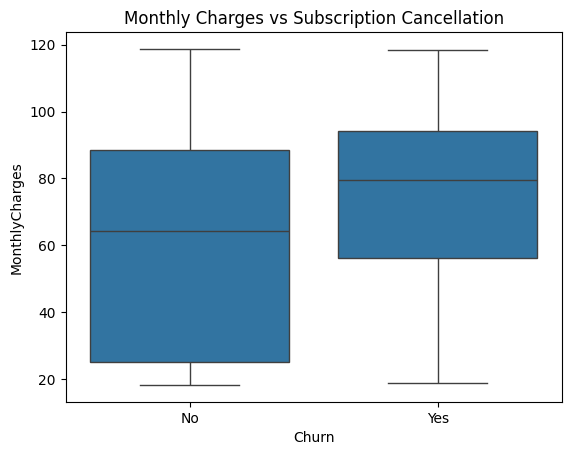

In [ ]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Subscription Cancellation")
plt.show()

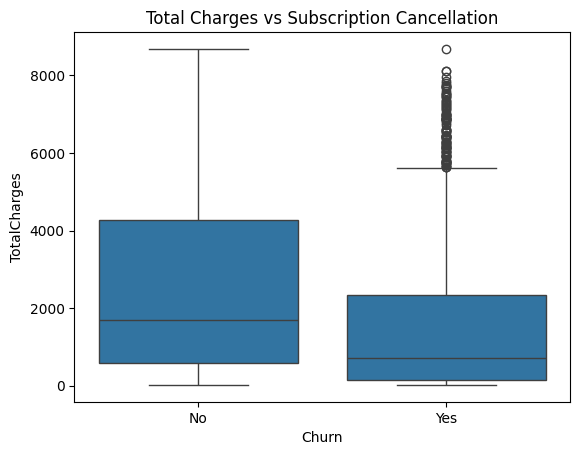

In [ ]:
sns.boxplot(data=df, x="Churn", y="TotalCharges")
plt.title("Total Charges vs Subscription Cancellation")
plt.show()

<Axes: xlabel='tenure', ylabel='MonthlyCharges'>

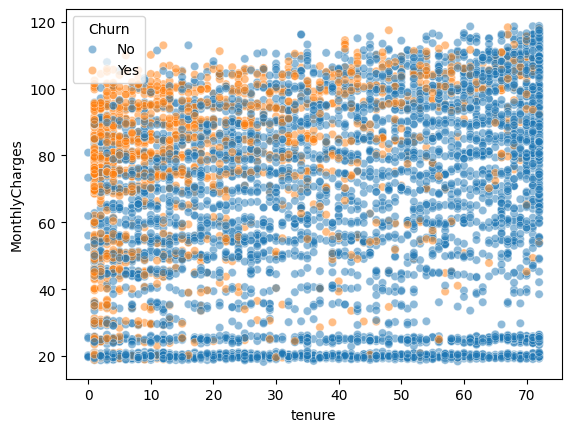

In [ ]:
sns.scatterplot(data=df, x="tenure", y="MonthlyCharges", hue="Churn", alpha=0.5)


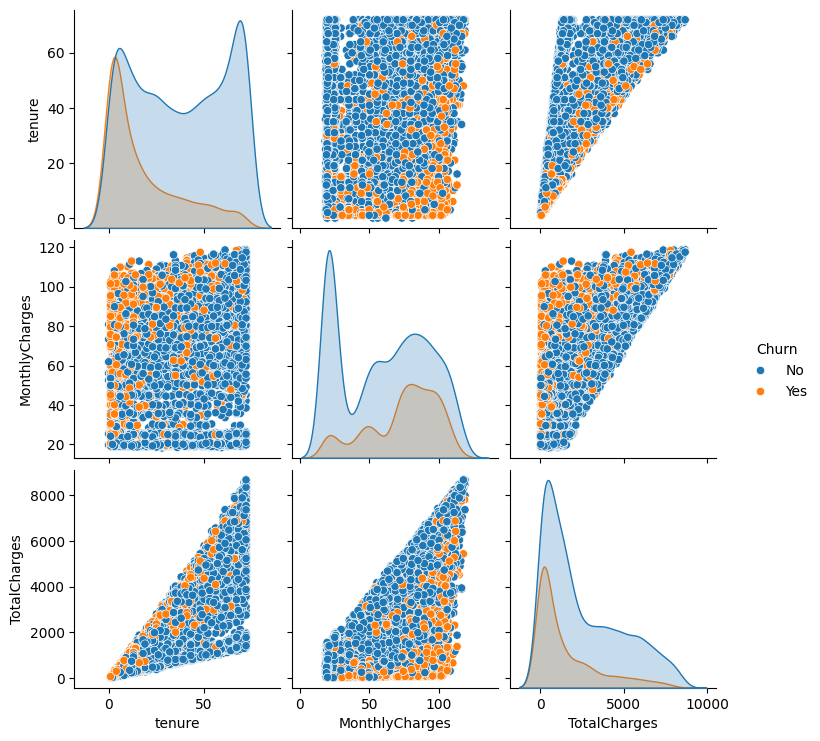

In [ ]:
sns.pairplot(df, vars=["tenure", "MonthlyCharges", "TotalCharges"], hue="Churn", diag_kind="kde")

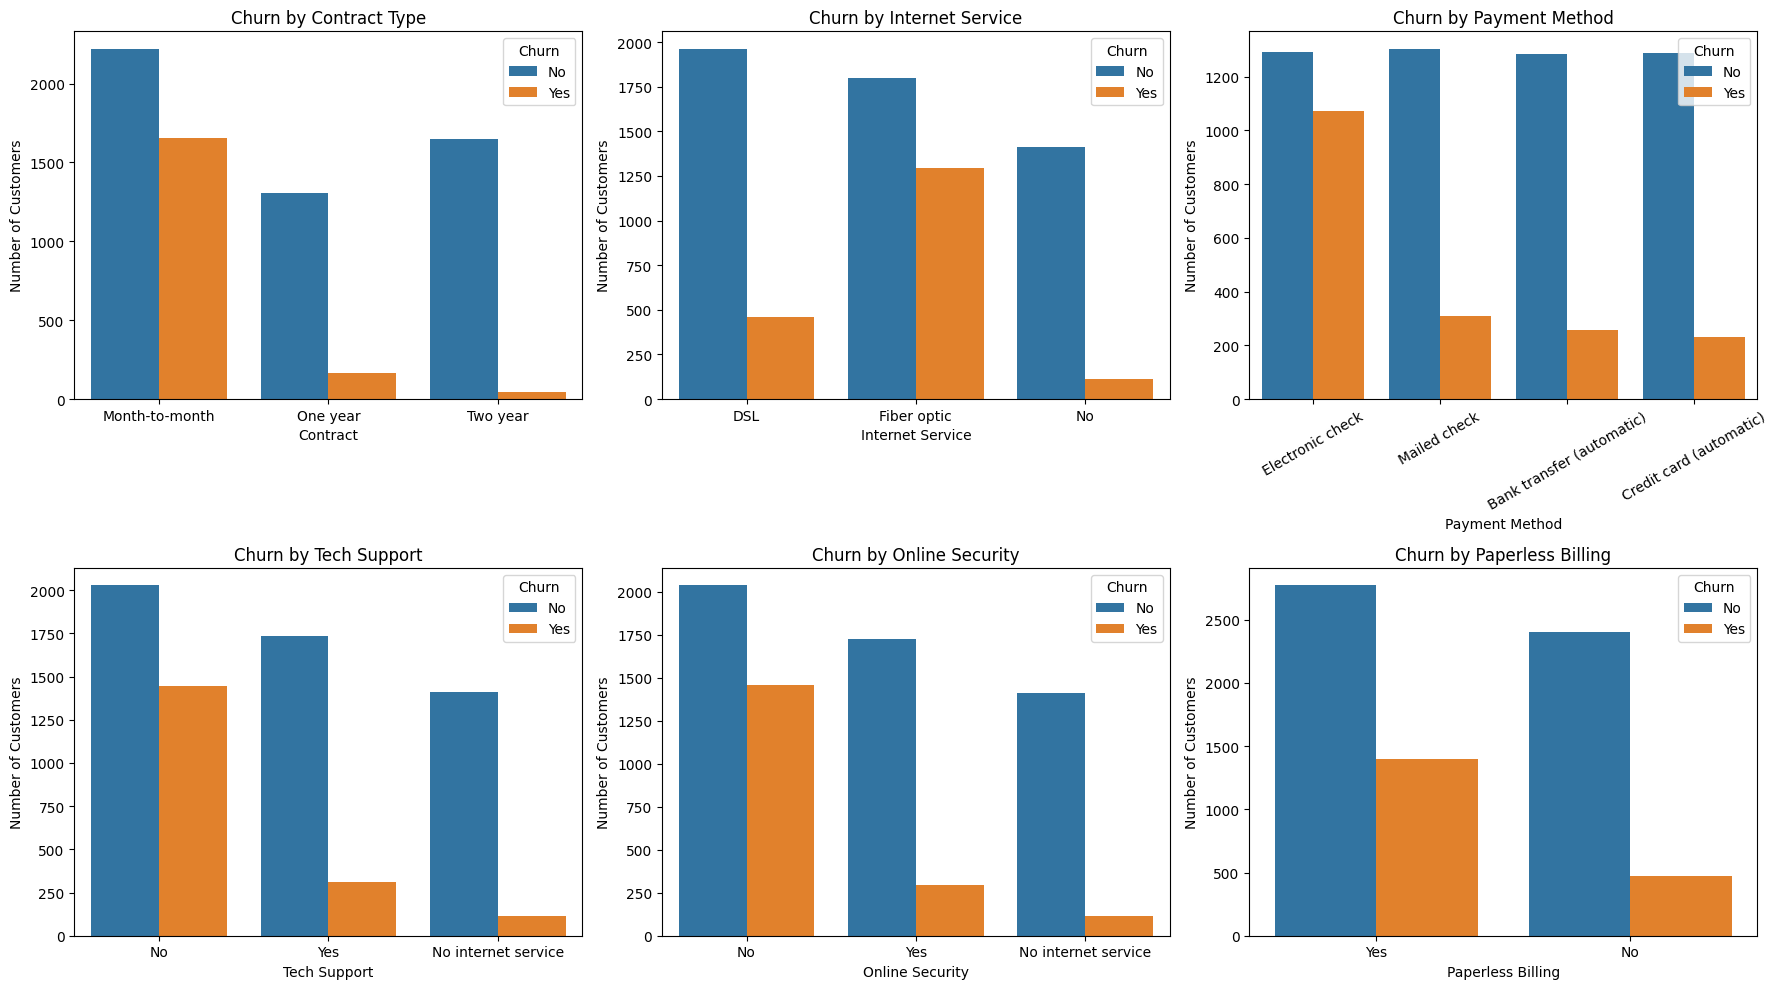

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Contract
sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[0, 0])
axes[0, 0].set_title("Churn by Contract Type")
axes[0, 0].set_xlabel("Contract")
axes[0, 0].set_ylabel("Number of Customers")

# 2. Internet Service
sns.countplot(data=df, x="InternetService", hue="Churn", ax=axes[0, 1])
axes[0, 1].set_title("Churn by Internet Service")
axes[0, 1].set_xlabel("Internet Service")
axes[0, 1].set_ylabel("Number of Customers")

# 3. Payment Method
sns.countplot(data=df, x="PaymentMethod", hue="Churn", ax=axes[0, 2])
axes[0, 2].set_title("Churn by Payment Method")
axes[0, 2].set_xlabel("Payment Method")
axes[0, 2].set_ylabel("Number of Customers")
axes[0, 2].tick_params(axis="x", rotation=30)

# 4. Tech Support
sns.countplot(data=df, x="TechSupport", hue="Churn", ax=axes[1, 0])
axes[1, 0].set_title("Churn by Tech Support")
axes[1, 0].set_xlabel("Tech Support")
axes[1, 0].set_ylabel("Number of Customers")

# 5. Online Security
sns.countplot(data=df, x="OnlineSecurity", hue="Churn", ax=axes[1, 1])
axes[1, 1].set_title("Churn by Online Security")
axes[1, 1].set_xlabel("Online Security")
axes[1, 1].set_ylabel("Number of Customers")

# 6. Paperless Billing
sns.countplot(data=df, x="PaperlessBilling", hue="Churn", ax=axes[1, 2])
axes[1, 2].set_title("Churn by Paperless Billing")
axes[1, 2].set_xlabel("Paperless Billing")
axes[1, 2].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Remaining categorical features vs. Churn
The previous grid covered Contract, InternetService, PaymentMethod, TechSupport, OnlineSecurity, and PaperlessBilling. These are the rest.

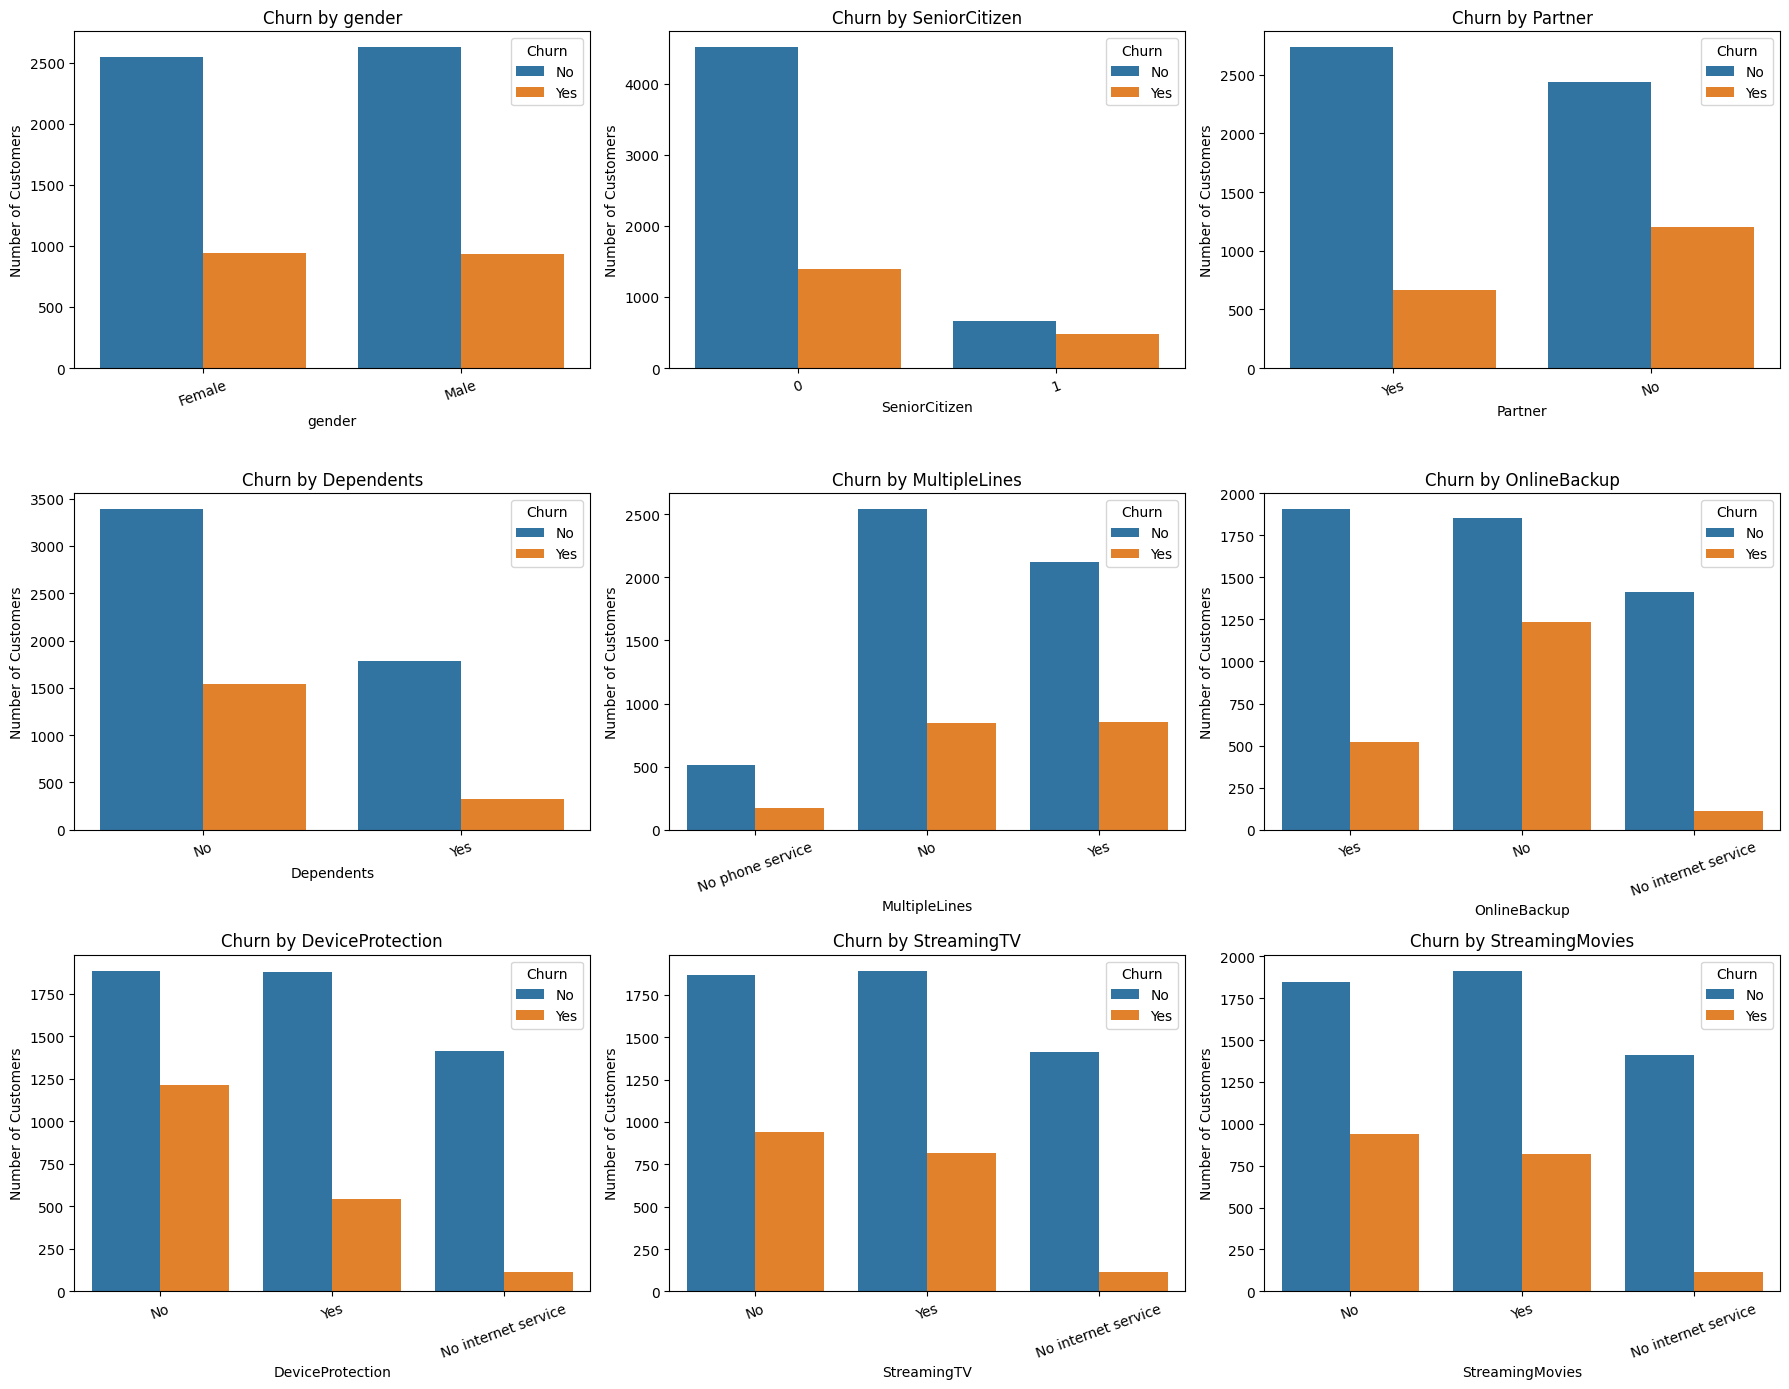

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(18, 14))

remaining_cat_cols = [
    "gender", "SeniorCitizen", "Partner", "Dependents",
    "MultipleLines", "OnlineBackup", "DeviceProtection",
    "StreamingTV", "StreamingMovies",
]

for ax, col in zip(axes.flatten(), remaining_cat_cols):
    sns.countplot(data=df, x=col, hue="Churn", ax=ax)
    ax.set_title(f"Churn by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of Customers")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


### Skewness of numeric features

In [ ]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].skew()


,0
tenure,0.239540
MonthlyCharges,-0.220524
TotalCharges,0.961642


### Churn rate (not raw counts) by contract type
Raw counts in the grid above are affected by how many customers are in each group.

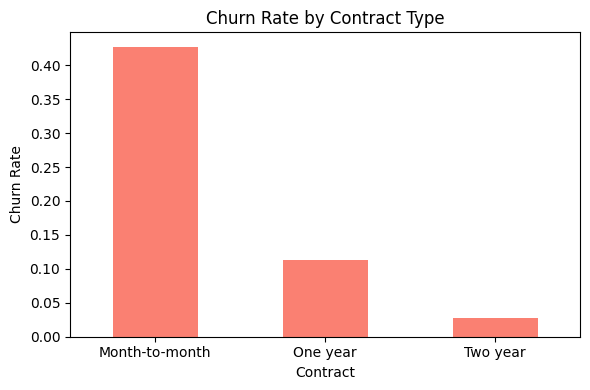

,Churn_bin
Contract,
Month-to-month,0.427097
One year,0.112695
Two year,0.028319


In [ ]:
churn_rate_by_contract = (
    df.assign(Churn_bin=df["Churn"].map({"No": 0, "Yes": 1}))
    .groupby("Contract")["Churn_bin"]
    .mean()
    .sort_values(ascending=False)
)

churn_rate_by_contract.plot(kind="bar", figsize=(6, 4), color="salmon")
plt.title("Churn Rate by Contract Type")
plt.ylabel("Churn Rate")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

churn_rate_by_contract


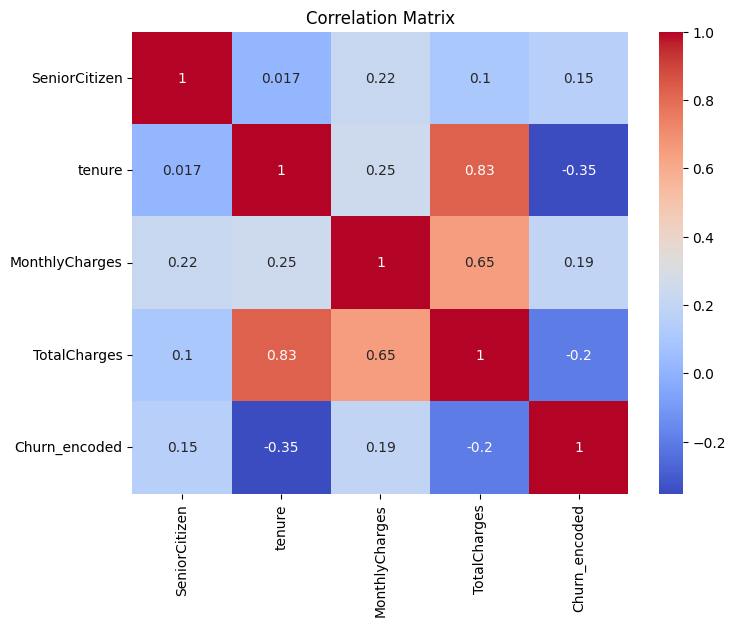

In [ ]:
df["Churn_encoded"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

df[["tenure", "MonthlyCharges", "TotalCharges", "Churn_encoded"]].corr()

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

# Preprocessing

In [ ]:
df = df.drop("customerID", axis=1)

In [ ]:
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [ ]:
df = df.dropna()

### Consolidate redundant categories


In [ ]:
service_cols = [
    "MultipleLines", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
]

for col in service_cols:
    df[col] = df[col].replace({"No internet service": "No", "No phone service": "No"})


In [ ]:
X = df.drop(["Churn", "Churn_encoded"], axis=1)
y = df["Churn"]

y = y.map({
    "No": 0,
    "Yes": 1
})

In [ ]:
X = pd.get_dummies(X, drop_first=True)

In [ ]:
corr_matrix = X.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

high_corr_pairs = upper.stack().sort_values(ascending=False)
print("Top correlated feature pairs (check for redundancy):")
print(high_corr_pairs.head(10))


Top correlated feature pairs (check for redundancy):
tenure           TotalCharges                   0.825880
MonthlyCharges   InternetService_Fiber optic    0.787195
                 InternetService_No             0.763191
                 TotalCharges                   0.651065
                 StreamingTV_Yes                0.629668
                 StreamingMovies_Yes            0.627235
tenure           Contract_Two year              0.563801
StreamingTV_Yes  StreamingMovies_Yes            0.533380
TotalCharges     DeviceProtection_Yes           0.522881
                 StreamingMovies_Yes            0.519867
dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### Scaling only the continuous features


In [ ]:
from sklearn.preprocessing import StandardScaler

continuous_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
X_test_scaled[continuous_cols] = scaler.transform(X_test[continuous_cols])

X_train = X_train_scaled
X_test = X_test_scaled


In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Churn
0    4130
1    1495
Name: count, dtype: int64

After SMOTE:
Churn
0    4130
1    4130
Name: count, dtype: int64


### Final check before modeling

In [ ]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print()
print("Any NaNs in X_train?", X_train.isnull().values.any())
print("Any NaNs in X_test?", X_test.isnull().values.any())
print()
print("X_train dtypes:\n", X_train.dtypes.value_counts())
print()
print("Churn distribution in y_train:\n", y_train.value_counts(normalize=True))
print()
print("Churn distribution in y_test:\n", y_test.value_counts(normalize=True))


X_train shape: (5625, 23)
X_test shape: (1407, 23)

Any NaNs in X_train? False
Any NaNs in X_test? False

X_train dtypes:
 bool       19
float64     3
int64       1
Name: count, dtype: int64

Churn distribution in y_train:
 Churn
0    0.734222
1    0.265778
Name: proportion, dtype: float64

Churn distribution in y_test:
 Churn
0    0.734186
1    0.265814
Name: proportion, dtype: float64


##PCA


In [ ]:
# PCA - Principal Component Analysis

from sklearn.decomposition import PCA

# Keeping 95% of the information
pca = PCA(n_components=0.95)

# Fit PCA
X_train_pca = pca.fit_transform(X_train_smote)

# Apply PCA to test data
X_test_pca = pca.transform(X_test)

print("Original number of features:", X_train_smote.shape[1])
print("Number of PCA components:", X_train_pca.shape[1])

print("X_train after PCA:", X_train_pca.shape)
print("X_test after PCA:", X_test_pca.shape)

print("Total explained variance:",
      pca.explained_variance_ratio_.sum())

Original number of features: 23
Number of PCA components: 17
X_train after PCA: (8260, 17)
X_test after PCA: (1407, 17)
Total explained variance: 0.961424973432145


# Logistic Regression


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix, classification_report
from sklearn.metrics import roc_auc_score


log_model = LogisticRegression(max_iter=1000)

# Train
log_model.fit(X_train_pca, y_train_smote)

# Predict churn for the test data
y_pred = log_model.predict(X_test_pca)
y_prob = log_model.predict_proba(X_test_pca)[:, 1]


print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.738450604122246
Precision: 0.5054744525547445
Recall: 0.7406417112299465
F1 Score: 0.6008676789587852
ROC-AUC: 0.828228616096619

Confusion Matrix:
[[762 271]
 [ 97 277]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.74      0.81      1033
           1       0.51      0.74      0.60       374

    accuracy                           0.74      1407
   macro avg       0.70      0.74      0.70      1407
weighted avg       0.79      0.74      0.75      1407



# Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix, classification_report
from sklearn.metrics import roc_auc_score

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train
rf_model.fit(X_train_smote, y_train_smote)

# Predict churn
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Evaluation
print("Random Forest Results")
print("---------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Results
---------------------
Accuracy: 0.7661691542288557
Precision: 0.5534441805225653
Recall: 0.6229946524064172
F1 Score: 0.5861635220125786
ROC-AUC: 0.8138592231753214

Confusion Matrix:
[[845 188]
 [141 233]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.82      0.84      1033
           1       0.55      0.62      0.59       374

    accuracy                           0.77      1407
   macro avg       0.71      0.72      0.71      1407
weighted avg       0.78      0.77      0.77      1407



# XGBoost Classifier

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix, classification_report
from sklearn.metrics import roc_auc_score

# Create the XGBoost model
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)

# Train
xgb_model.fit(X_train_smote, y_train_smote)

# Predict churn for the original test data
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Evaluate
print("XGBoost Results")
print("----------------")

print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1 Score:", f1_score(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

XGBoost Results
----------------
Accuracy: 0.749822316986496
Precision: 0.5215686274509804
Recall: 0.7112299465240641
F1 Score: 0.6018099547511312
ROC-AUC: 0.82992141677581

Confusion Matrix:
[[789 244]
 [108 266]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.76      0.82      1033
           1       0.52      0.71      0.60       374

    accuracy                           0.75      1407
   macro avg       0.70      0.74      0.71      1407
weighted avg       0.78      0.75      0.76      1407



# Original vs SMOTE vs NearMiss vs class weighting

Compare the same four model families on the untouched `X_test` / `y_test` (~73/27) under four training arms. SMOTE data (`X_train_smote` / `y_train_smote`) is reused as-is from the earlier cell.


In [ ]:
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)


def evaluate_model(model, X_tr, y_tr, X_te, y_te, use_pca=False):
    estimator = clone(model)
    if use_pca:
        pca_fit = PCA(n_components=0.95)
        X_tr_use = pca_fit.fit_transform(X_tr)
        X_te_use = pca_fit.transform(X_te)
    else:
        X_tr_use, X_te_use = X_tr, X_te

    estimator.fit(X_tr_use, y_tr)
    y_pred = estimator.predict(X_te_use)
    y_prob = estimator.predict_proba(X_te_use)[:, 1]

    return {
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred, zero_division=0),
        "Recall": recall_score(y_te, y_pred, zero_division=0),
        "F1": f1_score(y_te, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_te, y_prob),
        "confusion_matrix": confusion_matrix(y_te, y_pred),
    }


def run_all_models(resampling_label, X_tr, y_tr, model_specs):
    rows = []
    for model_name, model, use_pca in model_specs:
        result = evaluate_model(
            model, X_tr, y_tr, X_test, y_test, use_pca=use_pca
        )
        print(f"{model_name} | {resampling_label}")
        print(result["confusion_matrix"])
        print()
        rows.append({
            "Model": model_name,
            "Arm": resampling_label,
            "Accuracy": result["Accuracy"],
            "Precision": result["Precision"],
            "Recall": result["Recall"],
            "F1": result["F1"],
            "ROC-AUC": result["ROC-AUC"],
        })
    return rows


In [ ]:
!pip install catboost
from catboost import CatBoostClassifier


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.3 MB/s eta 0:00:00


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

log_template = LogisticRegression(max_iter=1000)
rf_template = RandomForestClassifier(n_estimators=100, random_state=42)
xgb_template = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
)

model_specs = [
    ("Logistic Regression", log_template, True),
    ("Random Forest", rf_template, False),
    ("XGBoost", xgb_template, False),
]

catboost_template = CatBoostClassifier(
    iterations=300,
    depth=4,
    learning_rate=0.05,
    subsample=0.8,
    rsm=0.8,
    bootstrap_type="Bernoulli",
    random_state=42,
    verbose=False,
)
model_specs.append(("CatBoost", catboost_template, False))

results_original = run_all_models("Original", X_train, y_train, model_specs)


Logistic Regression | Original
[[929 104]
 [179 195]]

Random Forest | Original
[[922 111]
 [186 188]]

XGBoost | Original
[[914 119]
 [178 196]]

CatBoost | Original
[[926 107]
 [176 198]]



In [ ]:
results_smote = run_all_models(
    "SMOTE", X_train_smote, y_train_smote, model_specs
)


Logistic Regression | SMOTE
[[762 271]
 [ 97 277]]

Random Forest | SMOTE
[[845 188]
 [141 233]]

XGBoost | SMOTE
[[789 244]
 [108 266]]

CatBoost | SMOTE
[[773 260]
 [ 89 285]]



In [ ]:
from imblearn.under_sampling import NearMiss

nearmiss = NearMiss(version=1)
X_train_under, y_train_under = nearmiss.fit_resample(X_train, y_train)

print("Before undersampling:")
print(y_train.value_counts())

print("\nAfter undersampling (NearMiss):")
print(y_train_under.value_counts())


Before undersampling:
Churn
0    4130
1    1495
Name: count, dtype: int64

After undersampling (NearMiss):
Churn
0    1495
1    1495
Name: count, dtype: int64


In [ ]:
results_nearmiss = run_all_models(
    "NearMiss", X_train_under, y_train_under, model_specs
)


Logistic Regression | NearMiss
[[690 343]
 [ 94 280]]

Random Forest | NearMiss
[[472 561]
 [ 94 280]]

XGBoost | NearMiss
[[424 609]
 [ 87 287]]

CatBoost | NearMiss
[[426 607]
 [ 76 298]]



In [ ]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

log_weighted = LogisticRegression(max_iter=1000, class_weight="balanced")
rf_weighted = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
)
xgb_weighted = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    scale_pos_weight=scale_pos_weight,
)

model_specs_weighted = [
    ("Logistic Regression", log_weighted, True),
    ("Random Forest", rf_weighted, False),
    ("XGBoost", xgb_weighted, False),
]

# CatBoost equivalent of class_weight='balanced' is auto_class_weights='Balanced'
# (class_weights='Balanced' is not a valid CatBoost argument).
catboost_weighted = CatBoostClassifier(
    iterations=300,
    depth=4,
    learning_rate=0.05,
    subsample=0.8,
    rsm=0.8,
    bootstrap_type="Bernoulli",
    random_state=42,
    verbose=False,
    auto_class_weights="Balanced",
)
model_specs_weighted.append(("CatBoost", catboost_weighted, False))


In [ ]:
results_weighted = run_all_models(
    "Class-Weighted", X_train, y_train, model_specs_weighted
)


Logistic Regression | Class-Weighted
[[757 276]
 [ 86 288]]

Random Forest | Class-Weighted
[[930 103]
 [185 189]]

XGBoost | Class-Weighted
[[745 288]
 [ 84 290]]

CatBoost | Class-Weighted
[[741 292]
 [ 71 303]]



In [ ]:
arm_order = ["Original", "SMOTE", "NearMiss", "Class-Weighted"]

comparison_df = pd.DataFrame(
    results_original + results_smote + results_nearmiss + results_weighted
)
comparison_df["Arm"] = pd.Categorical(
    comparison_df["Arm"], categories=arm_order, ordered=True
)
comparison_df = comparison_df.sort_values(["Model", "Arm"]).reset_index(drop=True)
comparison_df


,Model,Arm,Accuracy,Precision,Recall,F1,ROC-AUC
0,CatBoost,Original,0.798863,0.649180,0.529412,0.583211,0.840918
1,CatBoost,SMOTE,0.751955,0.522936,0.762032,0.620239,0.835998
2,CatBoost,NearMiss,0.514570,0.329282,0.796791,0.465989,0.583250
3,CatBoost,Class-Weighted,0.742004,0.509244,0.810160,0.625387,0.839602
4,Logistic Regression,Original,0.798863,0.652174,0.521390,0.579495,0.831306
5,Logistic Regression,SMOTE,0.738451,0.505474,0.740642,0.600868,0.828229
6,Logistic Regression,NearMiss,0.689410,0.449438,0.748663,0.561685,0.764089
7,Logistic Regression,Class-Weighted,0.742715,0.510638,0.770053,0.614072,0.831552
8,Random Forest,Original,0.788913,0.628763,0.502674,0.558692,0.817699
9,Random Forest,SMOTE,0.766169,0.553444,0.622995,0.586164,0.813859


### Interpretation: Original vs SMOTE vs NearMiss vs class weighting

Read **Recall** and **Precision** as the churn-class (label = 1) metrics in `comparison_df`. All **16 rows** (4 models x 4 arms) are scored on the same original `X_test` / `y_test` (~73% non-churn / ~27% churn).

**Original.** Training stays at the true prior. The default 0.5 cutoff is therefore aligned with test. Expect **higher precision and lower recall**: the models can sit on the majority class and miss churners (more false negatives). This is the baseline the other arms are trying to beat on recall without wrecking precision.

**SMOTE.** Synthetic minority rows force a 50/50 train prior. Expect **higher recall** than Original (fewer missed churners) and **lower precision** (more false positives). The train/test ratio no longer matches: the model behaves as if churn were as common as non-churn, which inflates predicted churn on a 73/27 test set.

**NearMiss.** Same 50/50 train prior as SMOTE, so the same threshold mismatch applies, and recall often rises versus Original. Unlike SMOTE, it **deletes majority customers** and keeps only those nearest the minority class. That can preserve a useful decision boundary, but it throws away easy long-tenure non-churners and trains on a much smaller set. Precision is often the weakest of the four arms when those discarded majority points were what kept false positives down.

**Class-Weighted.** Same original `X_train` / `y_train` (no extra rows, no dropped rows). `class_weight="balanced"` / `scale_pos_weight` / CatBoost `auto_class_weights="Balanced"` up-weight the churn class in the loss so the learner cares more about recall **without changing the empirical 73/27 ratio**. The default 0.5 cutoff is therefore closer to the test prior than after SMOTE or NearMiss. For each model, compare the Class-Weighted row to SMOTE and NearMiss: if recall is in the same range while precision (and often F1) is closer to Original, class weighting recovered minority sensitivity without SMOTE's prior mismatch and without NearMiss's data loss.

**CatBoost vs Random Forest and XGBoost.** CatBoost is a boosting tree model like XGBoost, with ordered boosting that is often competitive with (or better than) XGBoost on tabular data that includes many categoricals. Here it is trained on the **same one-hot encoded matrix** as RF and XGBoost, not on raw category columns, so any gain is from the boosting procedure rather than native categorical handling. In `comparison_df`, compare CatBoost to XGBoost first (closest sibling: similar depth, learning rate, and iteration budget), then to Random Forest:

- On the **Original** arm, CatBoost and XGBoost typically sit above RF on ROC-AUC/F1; check whether CatBoost's recall is closer to XGBoost than to RF's more conservative majority-leaning predictions.
- On **SMOTE** and **NearMiss**, all three tree models should lift recall versus Original. If CatBoost keeps **higher precision or F1 than XGBoost** on those 50/50 arms, it is handling the prior mismatch more gracefully; if it tracks XGBoost closely, the two boosters are interchangeable on this encoding.
- On **Class-Weighted**, compare whether CatBoost's balanced weights recover SMOTE-like recall with less precision loss than RF (which can over-emphasize minority leaves) and similarly to XGBoost's `scale_pos_weight`.

Per model, walk down the four Arm rows in `comparison_df` and check which arm gives the best recall-precision tradeoff (F1) rather than recall alone.


# Result Visualization

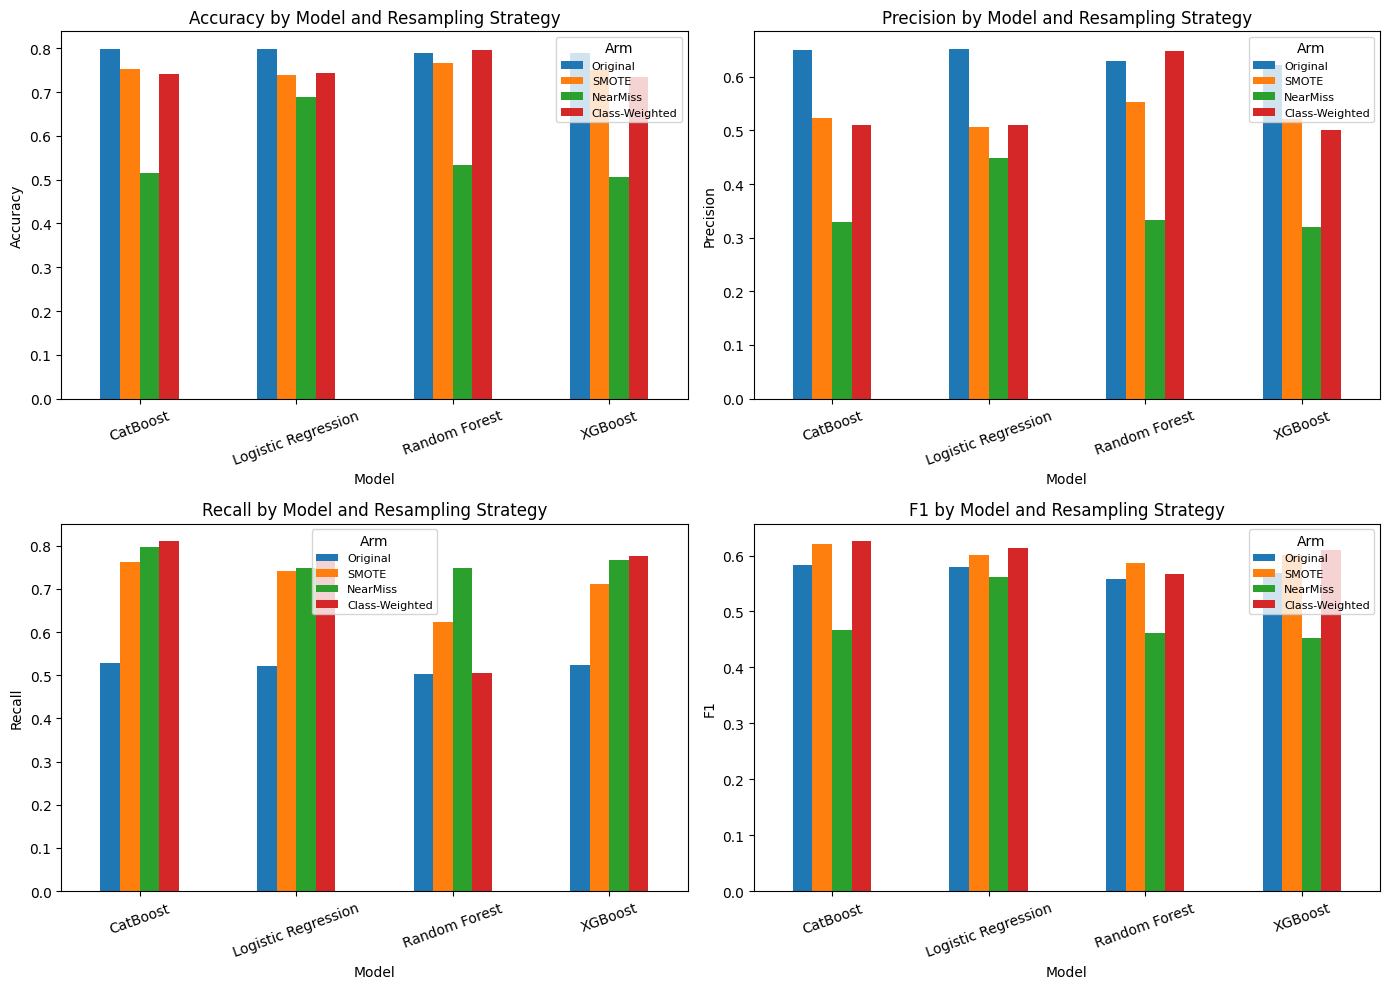

In [ ]:
#Grouped bar chart comparing metrics across the 4 arms, per model

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
metrics = ["Accuracy", "Precision", "Recall", "F1"]

for ax, metric in zip(axes.flatten(), metrics):
    pivot = comparison_df.pivot(index="Model", columns="Arm", values=metric)
    pivot = pivot[arm_order]  # keep consistent order
    pivot.plot(kind="bar", ax=ax, rot=20)
    ax.set_title(f"{metric} by Model and Resampling Strategy")
    ax.set_ylabel(metric)
    ax.legend(title="Arm", fontsize=8)

plt.tight_layout()
plt.show()

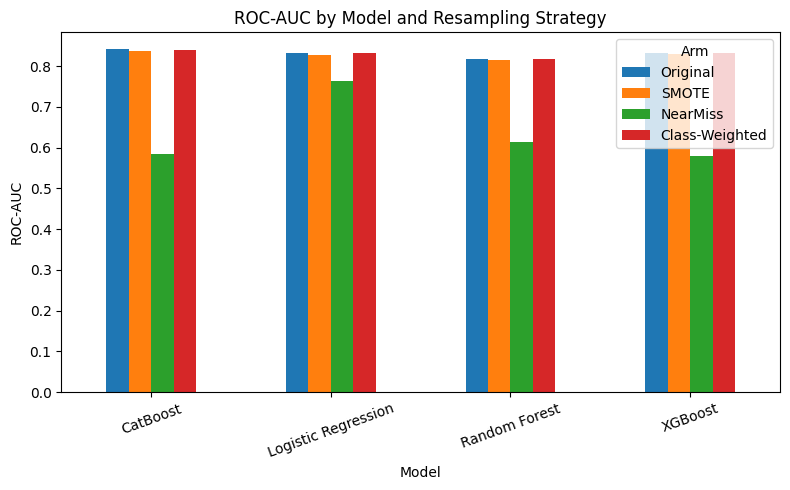

In [ ]:
#ROC-AUC comparison

pivot_auc = comparison_df.pivot(index="Model", columns="Arm", values="ROC-AUC")[arm_order]
pivot_auc.plot(kind="bar", figsize=(8, 5), rot=20)
plt.title("ROC-AUC by Model and Resampling Strategy")
plt.ylabel("ROC-AUC")
plt.legend(title="Arm")
plt.tight_layout()
plt.show()

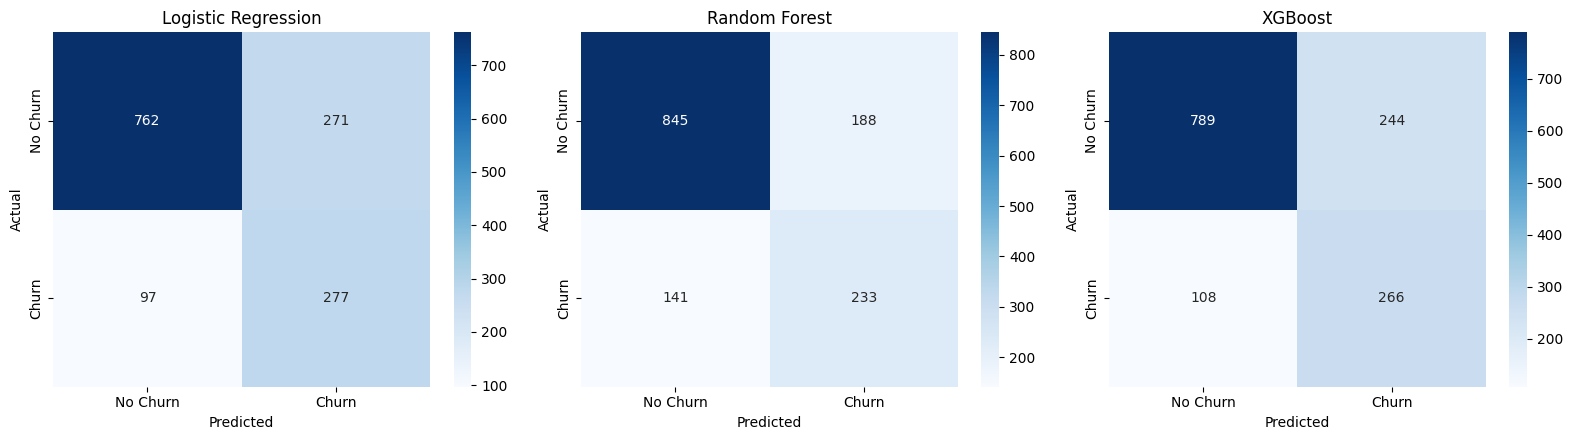

In [ ]:
#Confusion matrix heatmaps for the three original models (log_model, fr_model, xgb_model)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

cm_data = [
    ("Logistic Regression", confusion_matrix(y_test, y_pred)),
    ("Random Forest", confusion_matrix(y_test, y_pred_rf)),
    ("XGBoost", confusion_matrix(y_test, y_pred_xgb)),
]

for ax, (title, cm) in zip(axes, cm_data):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["No Churn", "Churn"], yticklabels=["No Churn", "Churn"])
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

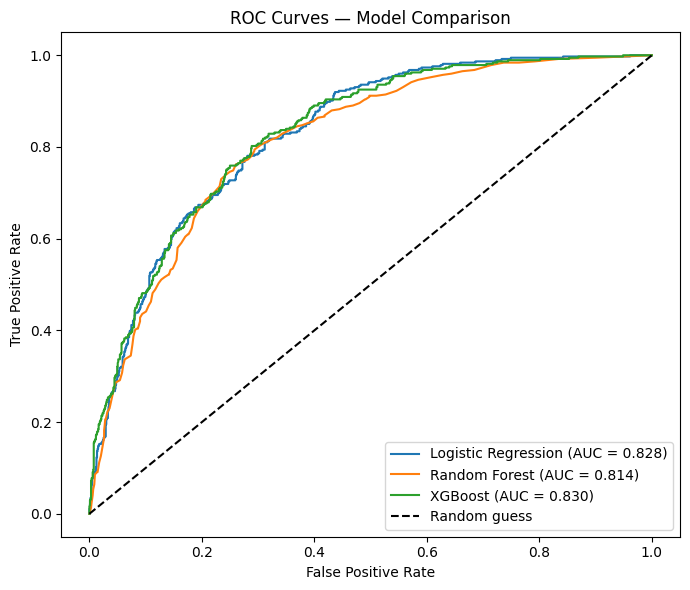

In [ ]:
#ROC Curves for all the three models

from sklearn.metrics import roc_curve

plt.figure(figsize=(7, 6))

for name, y_prob_model in [
    ("Logistic Regression", y_prob),
    ("Random Forest", y_prob_rf),
    ("XGBoost", y_prob_xgb),
]:
    fpr, tpr, _ = roc_curve(y_test, y_prob_model)
    auc = roc_auc_score(y_test, y_prob_model)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Model Comparison")
plt.legend()
plt.tight_layout()
plt.show()

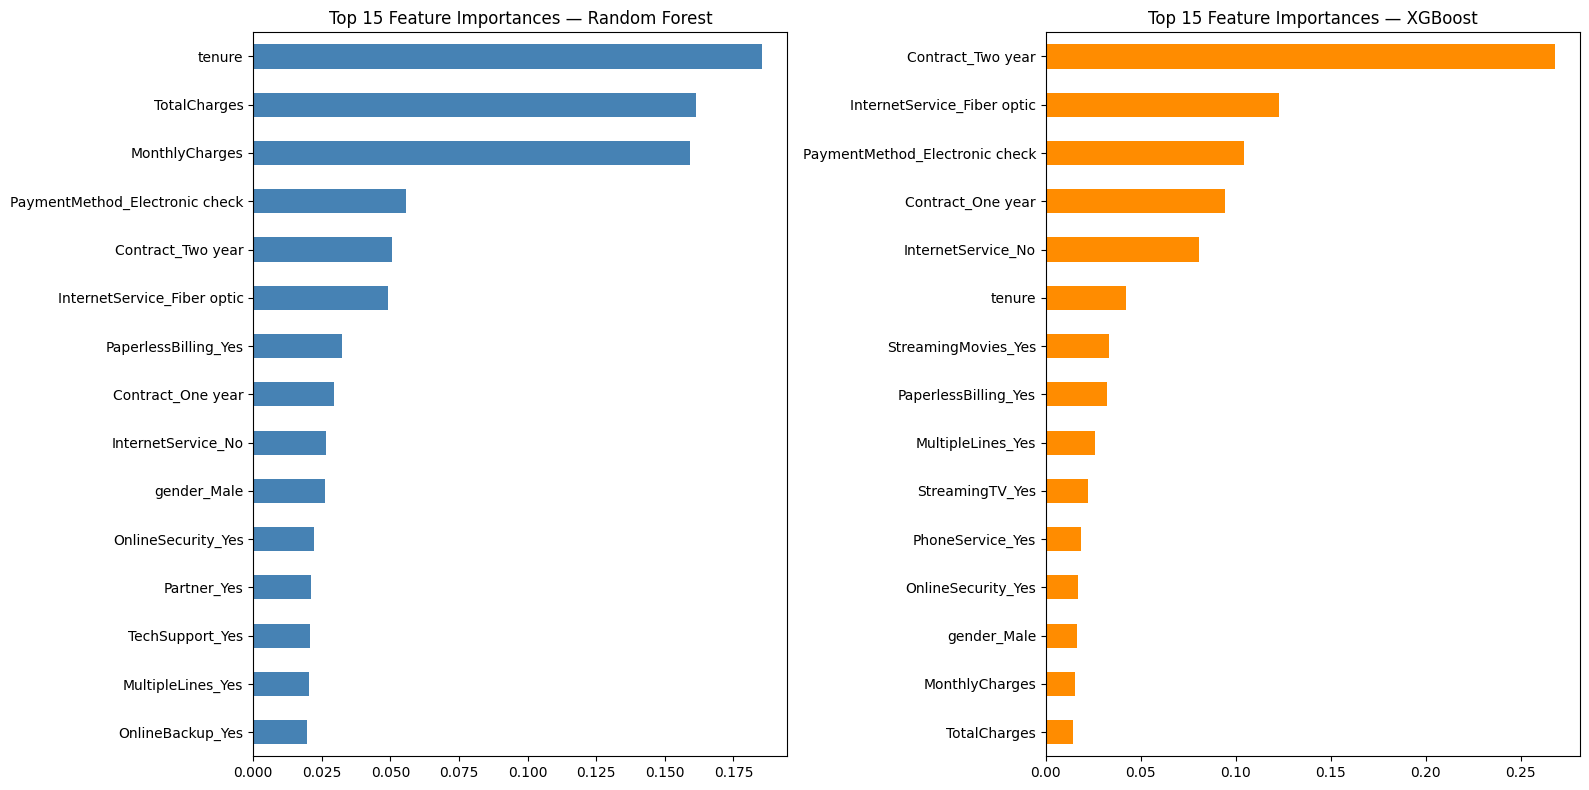

In [ ]:
#Feature importance (RF and XGBoost)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

rf_importance = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)
rf_importance.plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].invert_yaxis()
axes[0].set_title("Top 15 Feature Importances — Random Forest")

xgb_importance = pd.Series(xgb_model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)
xgb_importance.plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].invert_yaxis()
axes[1].set_title("Top 15 Feature Importances — XGBoost")

plt.tight_layout()
plt.show()

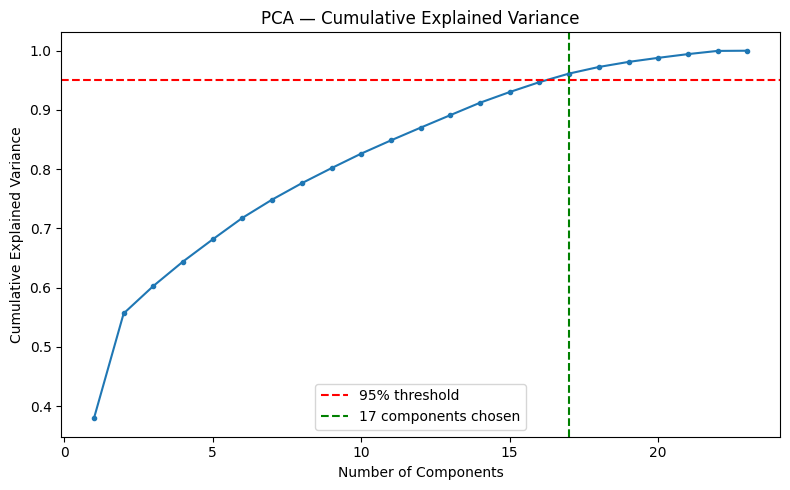

In [ ]:
#PCA cumulative explained variance, toexplain n_cmponents = 0.95 choice

pca_full = PCA().fit(X_train_smote)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumvar) + 1), cumvar, marker="o", markersize=3)
plt.axhline(0.95, color="red", linestyle="--", label="95% threshold")
plt.axvline(pca.n_components_, color="green", linestyle="--", label=f"{pca.n_components_} components chosen")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA — Cumulative Explained Variance")
plt.legend()
plt.tight_layout()
plt.show()